In [1]:
import pandas as pd
import numpy as np
import re
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score

# 1. Load the CSVs for all three models
qwen2b_df = pd.read_csv('/kaggle/input/datasets/ramakanthjogada/without-person-questions/qwen-2B-without-person.csv')
qwen3b_df = pd.read_csv('/kaggle/input/datasets/ramakanthjogada/without-person-questions/qwen-3B-without-person.csv')
smol_df = pd.read_csv('/kaggle/input/datasets/ramakanthjogada/without-person-questions/Smol-2.2B-without-person.csv')

# 2. Merge the dataframes on Image_Id and Ground_truth
merged_df = pd.merge(qwen2b_df[['Image_Id', 'Ground_truth', 'Qwen-2B']], qwen3b_df[['Image_Id', 'Qwen-3B']], on='Image_Id', how='inner')
merged_df = pd.merge(merged_df, smol_df[['Image_Id', 'Smol-2.2B']], on='Image_Id', how='inner')

# Helper to cleanly binarize standard answers (handles Yes/No variations)
def clean_and_binarize(val):
    if pd.isna(val):
        return None
    cleaned = str(val).strip().lower()
    cleaned = re.sub(r'[\.\!]+$', '', cleaned).strip()
    if cleaned in ['yes', 'y', '1', 'true']:
        return 1
    elif cleaned in ['no', 'n', '0', 'false']:
        return 0
    else:
        return None

gt_col = 'Ground_truth'
model_cols = ['Qwen-2B', 'Qwen-3B', 'Smol-2.2B']

pope_metrics = []

for model_name in model_cols:
    if model_name not in merged_df.columns:
        continue
        
    temp_df = pd.DataFrame({
        'y_true_raw': merged_df[gt_col],
        'y_pred_raw': merged_df[model_name]
    })
    
    temp_df['y_true'] = temp_df['y_true_raw'].apply(clean_and_binarize)
    temp_df['y_pred'] = temp_df['y_pred_raw'].apply(clean_and_binarize)
    
    clean_df = temp_df.dropna()
    
    y_true = clean_df['y_true'].astype(int).values
    y_pred = clean_df['y_pred'].astype(int).values
    
    if len(y_true) == 0:
        continue
        
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    fnr = fn / (fn + tp) if (fn + tp) > 0 else 0.0
    
    pope_metrics.append({
        "MODEL": model_name,
        "Valid_Rows": len(y_true),
        "TP": int(tp),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1_Score": f1,
        "FPR (False Positive Rate)": fpr,
        "FNR (False Negative Rate)": fnr
    })

# Create final DataFrame
df_pope_all = pd.DataFrame(pope_metrics)
display(df_pope_all)

# Save to CSV
df_pope_all.to_csv('pope_models_comparison-without-person.csv', index=False)
print("Saved POPE metrics comparison to 'pope_models_comparison-without-person.csv'")

,MODEL,Valid_Rows,TP,TN,FP,FN,Accuracy,Precision,Recall,F1_Score,FPR (False Positive Rate),FNR (False Negative Rate)
0,Qwen-2B,814,297,394,106,17,0.848894,0.736973,0.945860,0.828452,0.212000,0.054140
1,Qwen-3B,813,273,419,80,41,0.851169,0.773371,0.869427,0.818591,0.160321,0.130573
2,Smol-2.2B,814,272,387,113,42,0.809582,0.706494,0.866242,0.778255,0.226000,0.133758


Saved POPE metrics comparison to 'pope_models_comparison-without-person.csv'


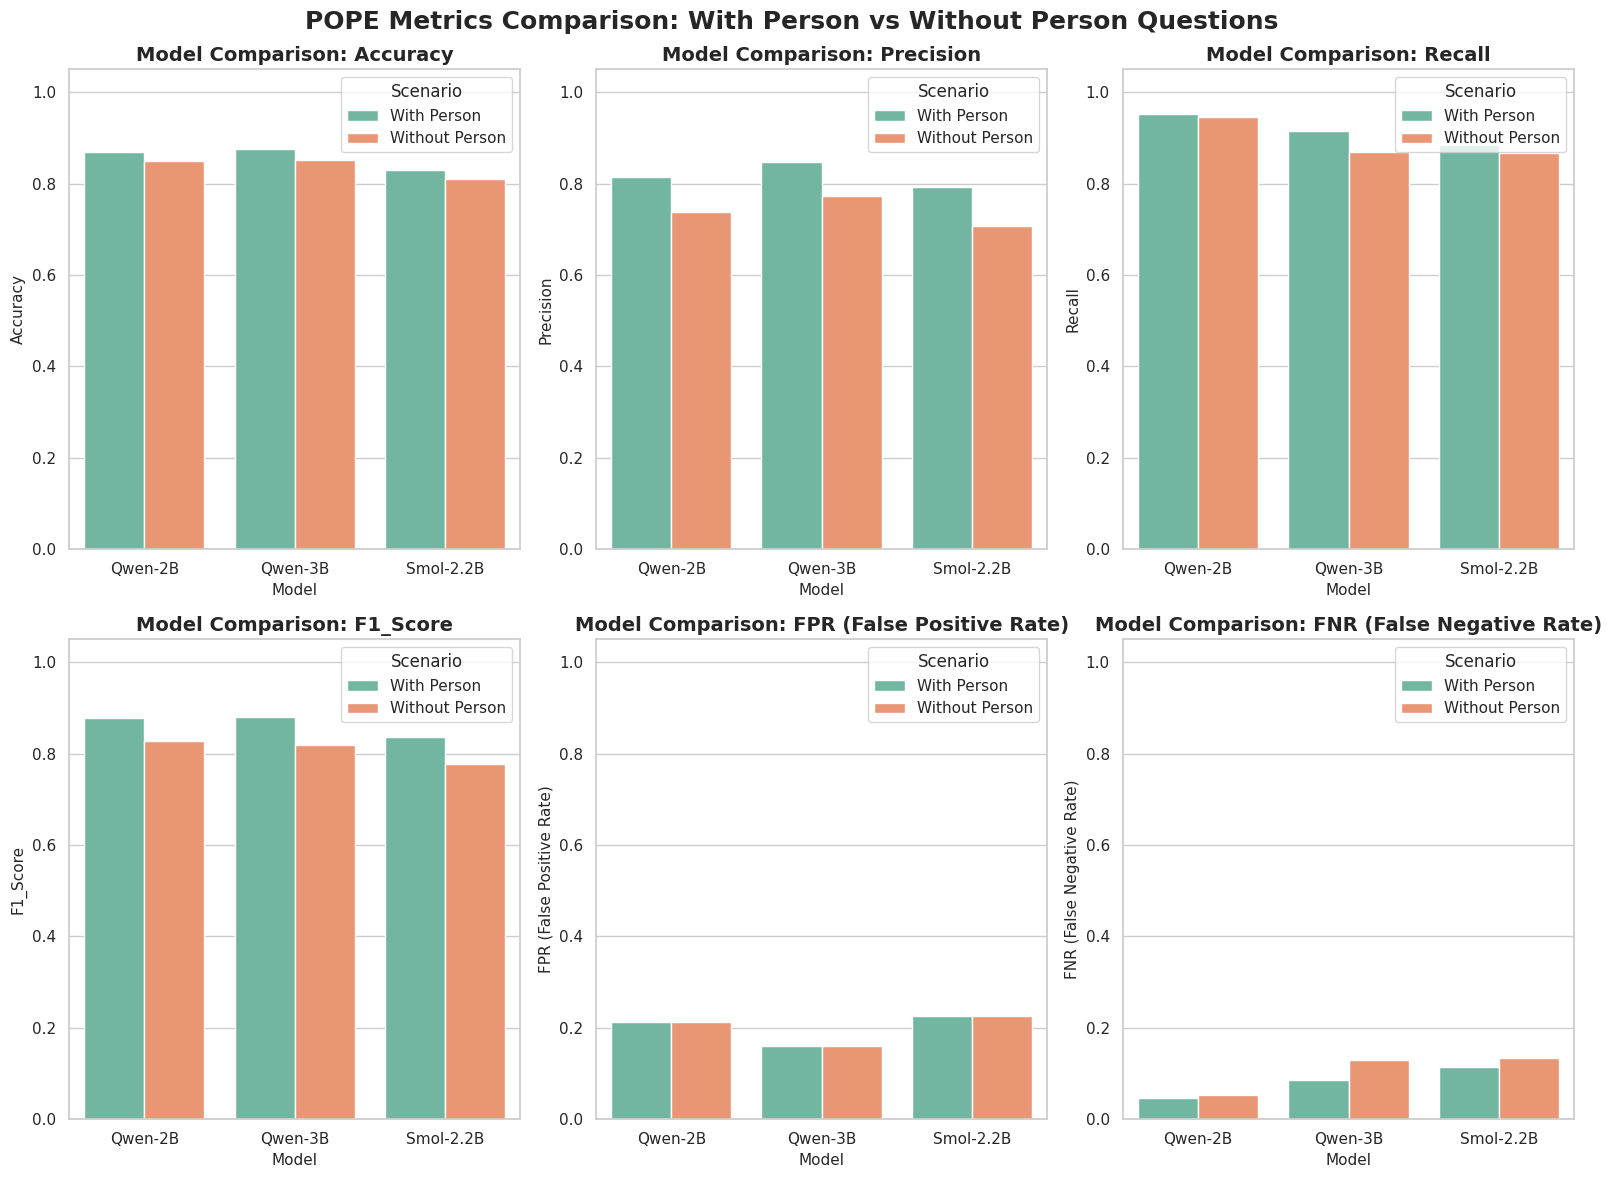

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the two evaluation datasets
# 'with-person' metrics are stored in the Excel file:
# /content/evaluation_metrics-pope-final-diff-models.xlsx
try:
    df_with_person = pd.read_csv('/kaggle/input/datasets/ramakanthjogada/ergregrg/pope_models_comparison-with-person.csv')
    # Standardize column naming
    if 'Variant' in df_with_person.columns and 'MODEL' not in df_with_person.columns:
        df_with_person = df_with_person.rename(columns={'Variant': 'MODEL'})
except Exception as e:
    print("Error loading with-person Excel:", e)
    # Fallback structure if needed
    df_with_person = pd.DataFrame()

# 'without-person' metrics are stored in:
# pope_models_comparison-without-person.csv
try:
    df_without_person = pd.read_csv('pope_models_comparison-without-person.csv')
except Exception as e:
    print("Error loading without-person CSV:", e)
    df_without_person = pd.DataFrame()

# Standardize model names in both datasets to ensure perfect matching
for df in [df_with_person, df_without_person]:
    if not df.empty and 'MODEL' in df.columns:
        df['MODEL'] = df['MODEL'].astype(str).str.strip().str.replace('_', '-')

# 2. Extract and align matching models
models_to_compare = ['Qwen-2B', 'Qwen-3B', 'Smol-2.2B']
df_with_filtered = df_with_person[df_with_person['MODEL'].isin(models_to_compare)].copy() if not df_with_person.empty else pd.DataFrame()
df_without_filtered = df_without_person[df_without_person['MODEL'].isin(models_to_compare)].copy() if not df_without_person.empty else pd.DataFrame()

# Add scenario identifiers
if not df_with_filtered.empty:
    df_with_filtered['Scenario'] = 'With Person'
if not df_without_filtered.empty:
    df_without_filtered['Scenario'] = 'Without Person'

# 3. Combine both dataframes
combined_df = pd.concat([df_with_filtered, df_without_filtered], ignore_index=True)

# Metrics to plot
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1_Score','FPR (False Positive Rate)','FNR (False Negative Rate)']

# 4. Generate side-by-side comparison plots
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.flatten()

sns.set_theme(style="whitegrid")

for idx, metric in enumerate(metrics_to_plot):
    ax = axes[idx]
    if metric in combined_df.columns:
        sns.barplot(
            data=combined_df,
            x='MODEL',
            y=metric,
            hue='Scenario',
            ax=ax,
            palette='Set2'
        )
        ax.set_title(f'Model Comparison: {metric}', fontsize=14, fontweight='bold')
        ax.set_xlabel('Model', fontsize=11)
        ax.set_ylabel(metric, fontsize=11)
        ax.set_ylim(0, 1.05)
        ax.legend(title='Scenario')
    else:
        ax.text(0.5, 0.5, f'Metric {metric} Not Found', ha='center', va='center')

plt.suptitle('POPE Metrics Comparison: With Person vs Without Person Questions', fontsize=18, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

In [7]:
df_without_person["Condition"] = "Without Person"
df_with_person["Condition"] = "With Person"

df_combined = pd.concat(
    [df_without_person, df_with_person],
    ignore_index=True
)

display(df_combined)

,MODEL,Valid_Rows,TP,TN,FP,FN,Accuracy,Precision,Recall,F1_Score,FPR (False Positive Rate),FNR (False Negative Rate),Condition
0,Qwen-2B,814,297,394,106,17,0.848894,0.736973,0.945860,0.828452,0.212000,0.054140,Without Person
1,Qwen-3B,813,273,419,80,41,0.851169,0.773371,0.869427,0.818591,0.160321,0.130573,Without Person
2,Smol-2.2B,814,272,387,113,42,0.809582,0.706494,0.866242,0.778255,0.226000,0.133758,Without Person
3,Qwen-2B,989,466,394,106,23,0.869565,0.814685,0.952965,0.878417,0.212000,0.047035,With Person
4,Qwen-3B,988,447,419,80,42,0.876518,0.848197,0.914110,0.879921,0.160321,0.085890,With Person
5,Smol-2.2B,989,433,387,113,56,0.829120,0.793040,0.885481,0.836715,0.226000,0.114519,With Person


In [8]:
df_combined = df_combined[
    ["Condition"] + [col for col in df_combined.columns if col != "Condition"]
]

display(df_combined)

,Condition,MODEL,Valid_Rows,TP,TN,FP,FN,Accuracy,Precision,Recall,F1_Score,FPR (False Positive Rate),FNR (False Negative Rate)
0,Without Person,Qwen-2B,814,297,394,106,17,0.848894,0.736973,0.945860,0.828452,0.212000,0.054140
1,Without Person,Qwen-3B,813,273,419,80,41,0.851169,0.773371,0.869427,0.818591,0.160321,0.130573
2,Without Person,Smol-2.2B,814,272,387,113,42,0.809582,0.706494,0.866242,0.778255,0.226000,0.133758
3,With Person,Qwen-2B,989,466,394,106,23,0.869565,0.814685,0.952965,0.878417,0.212000,0.047035
4,With Person,Qwen-3B,988,447,419,80,42,0.876518,0.848197,0.914110,0.879921,0.160321,0.085890
5,With Person,Smol-2.2B,989,433,387,113,56,0.829120,0.793040,0.885481,0.836715,0.226000,0.114519


In [9]:
df_combined.to_csv("evaluation-metrics-with-and-without-person.csv")